## Le but de ce modèle est d’estimer l’impact individuel potentiel d’une campagne email sur la probabilité d’achat, afin d’identifier les clients pour lesquels l’effet attendu de la campagne est le plus important.


In [1]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

/Users/madina/uplifting/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np 

In [3]:
from sklearn.model_selection import train_test_split

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [5]:
from sklearn.ensemble import RandomForestClassifier

In [6]:
path = kagglehub.dataset_download(
    "bofulee/kevin-hillstrom-minethatdata-e-mailanalytics"
)

print("Dossier :", path)

print("Fichiers :")
for f in os.listdir(path):
    print(f)

Dossier : /Users/madina/.cache/kagglehub/datasets/bofulee/kevin-hillstrom-minethatdata-e-mailanalytics/versions/1
Fichiers :
Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv


In [7]:
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "bofulee/kevin-hillstrom-minethatdata-e-mailanalytics",
    "Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv"
)

print(df.head())

   recency history_segment  history  mens  womens   zip_code  newbie channel  \
0       10  2) $100 - $200   142.44     1       0  Surburban       0   Phone   
1        6  3) $200 - $350   329.08     1       1      Rural       1     Web   
2        7  2) $100 - $200   180.65     0       1  Surburban       1     Web   
3        9  5) $500 - $750   675.83     1       0      Rural       1     Web   
4        2    1) $0 - $100    45.34     1       0      Urban       0     Web   

         segment  visit  conversion  spend  
0  Womens E-Mail      0           0    0.0  
1      No E-Mail      0           0    0.0  
2  Womens E-Mail      0           0    0.0  
3    Mens E-Mail      0           0    0.0  
4  Womens E-Mail      0           0    0.0  


### Definition du traitement et de la cible

In [8]:
# 1 = le client a reçu un email
# 0 = le client n'a pas reçu d'email

df['treatment'] = (
    df['segment'] != 'No E-Mail'
).astype(int)

# Variable cible :
# 1 = achat / conversion
# 0 = pas d'achat

y = df['conversion']

# Traitement
T = df['treatment']


### Variables disponibles avant la campagne

In [9]:
features = [
    'recency',
    'history',
    'history_segment',
    'mens',
    'womens',
    'zip_code',
    'newbie',
    'channel'
]

X = df[features].copy()


### Verification de la repartition

In [10]:


print("Répartition traitement :")
print(df['treatment'].value_counts())

print("\nTaux de conversion par groupe :")
print(
    df.groupby('treatment')['conversion'].mean()
)

print("\nTable traitement x conversion :")
print(
    pd.crosstab(
        df['treatment'],
        df['conversion']
    )
)

Répartition traitement :
treatment
1    42694
0    21306
Name: count, dtype: int64

Taux de conversion par groupe :
treatment
0    0.005726
1    0.010681
Name: conversion, dtype: float64

Table traitement x conversion :
conversion      0    1
treatment             
0           21184  122
1           42238  456


Le groupe traité contient 42 694 clients, contre 21 306 dans le groupe contrôle. Le taux de conversion est plus élevé chez les clients ayant reçu un email (1,07 %) que chez ceux n'en ayant pas reçu (0,57 %). Cette première observation suggère donc un effet positif de la campagne email sur les achats. Comme dans la partie a/b test.

### Split train/test

In [11]:
# Je veux préserver simultanément :
# - le traitement
# - la conversion
#
# Je crée donc une variable combinée

stratify_col = (
    T.astype(str) + "_" + y.astype(str)
)

X_train, X_test, y_train, y_test, T_train, T_test = train_test_split(
    X,
    y,
    T,
    test_size=0.30,
    random_state=42,
    stratify=stratify_col
)

### Encodage des variables categorielles 

In [12]:
categorical_features = [
    'history_segment',
    'zip_code',
    'channel'
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore'
            ),
            categorical_features
        )
    ],
    remainder='passthrough'
)


X_train_processed = preprocessor.fit_transform(
    X_train
)

X_test_processed = preprocessor.transform(
    X_test
)

### Separation traitement/controle

In [13]:
# Clients ayant reçu un email
train_treatment_mask = (
    T_train.values == 1
)

X_train_treatment = (
    X_train_processed[train_treatment_mask]
)

y_train_treatment = (
    y_train.values[train_treatment_mask]
)


# Clients n'ayant pas reçu d'email
train_control_mask = (
    T_train.values == 0
)

X_train_control = (
    X_train_processed[train_control_mask]
)

y_train_control = (
    y_train.values[train_control_mask]
)


print("\nNombre de clients dans le train :")
print("Traitement :", len(y_train_treatment))
print("Contrôle   :", len(y_train_control))


Nombre de clients dans le train :
Traitement : 29886
Contrôle   : 14914


### Modele treatement

In [14]:
model_treatment = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight=None,
    min_samples_leaf=50,
    n_jobs=-1
)

### Modele control

In [15]:
model_control = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight=None,
    min_samples_leaf=50,
    n_jobs=-1
)

### Entrainement

In [16]:
model_treatment.fit(
    X_train_treatment,
    y_train_treatment
)

model_control.fit(
    X_train_control,
    y_train_control
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the tota

### Predictions sur le test

In [17]:
# Probabilité d'achat SI le client reçoit un email

pred_treatment = model_treatment.predict_proba(
    X_test_processed
)[:, 1]


# Probabilité d'achat SI le client ne reçoit PAS d'email

pred_control = model_control.predict_proba(
    X_test_processed
)[:, 1]

### Calcul d'uplift individuel

In [34]:
uplift = (
    pred_treatment - pred_control
)

In [19]:
print(pd.DataFrame({
    'prob_email': pred_treatment,
    'prob_no_email': pred_control,
    'uplift': uplift
}).describe())

         prob_email  prob_no_email        uplift
count  19200.000000   19200.000000  19200.000000
mean       0.010538       0.005647      0.004891
std        0.007414       0.005124      0.006891
min        0.000355       0.000052     -0.019401
25%        0.004909       0.001678      0.000750
50%        0.008894       0.003970      0.003920
75%        0.014404       0.008384      0.008270
max        0.051260       0.038546      0.042925


Le modèle estime la probabilité d'achat avec et sans email. L'uplift correspond à la différence entre ces deux probabilités.
En moyenne, l'uplift estimé est de 0,49 point de pourcentage, ce qui indique un effet positif moyen de la campagne email sur la conversion. Cependant, cet effet varie selon les clients : certains présentent un uplift négatif, tandis que d'autres semblent davantage bénéficier de la campagne. C'est quasiment exactement l'effet moyen expérimental de +0,50 point.///

### Dataframe des resultats

In [20]:
results = X_test.copy()

results['prob_email'] = pred_treatment
results['prob_no_email'] = pred_control

results['uplift'] = uplift

results['treatment'] = T_test.values
results['conversion'] = y_test.values

### Tri par uplift

In [21]:
results_sorted = (
    results
    .sort_values(
        'uplift',
        ascending=False
    )
    .reset_index(drop=True)
)


# Rang
results_sorted['rank'] = (
    np.arange(1, len(results_sorted) + 1)
)


# Proportion de population
results_sorted['population_fraction'] = (
    results_sorted['rank']
    / len(results_sorted)
)


### Calculs cumules

In [22]:
results_sorted['cum_treatment'] = (
    results_sorted['treatment']
    .cumsum()
)

results_sorted['cum_control'] = (
    (1 - results_sorted['treatment'])
    .cumsum()
)


# Nombre de conversions dans le groupe traité
results_sorted['cum_conversion_treatment'] = (
    (
        results_sorted['treatment']
        * results_sorted['conversion']
    ).cumsum()
)


# Nombre de conversions dans le groupe contrôle
results_sorted['cum_conversion_control'] = (
    (
        (1 - results_sorted['treatment'])
        * results_sorted['conversion']
    ).cumsum()
)

### Calcul de la qini curve

In [23]:
# Formule :
#
# Qini(k) =
# conversions_traitement
# -
# conversions_controle
# *
# nombre_traitement / nombre_controle

results_sorted['qini'] = np.nan

mask = (
    results_sorted['cum_control'] > 0
)

results_sorted.loc[mask, 'qini'] = (
    results_sorted.loc[
        mask,
        'cum_conversion_treatment'
    ]
    -
    results_sorted.loc[
        mask,
        'cum_conversion_control'
    ]
    *
    (
        results_sorted.loc[
            mask,
            'cum_treatment'
        ]
        /
        results_sorted.loc[
            mask,
            'cum_control'
        ]
    )
)

### Baseline aleatoire

In [24]:

final_qini = (
    results_sorted['qini']
    .dropna()
    .iloc[-1]
)

results_sorted['random_baseline'] = (
    results_sorted['population_fraction']
    * final_qini
)

### Courbe qini

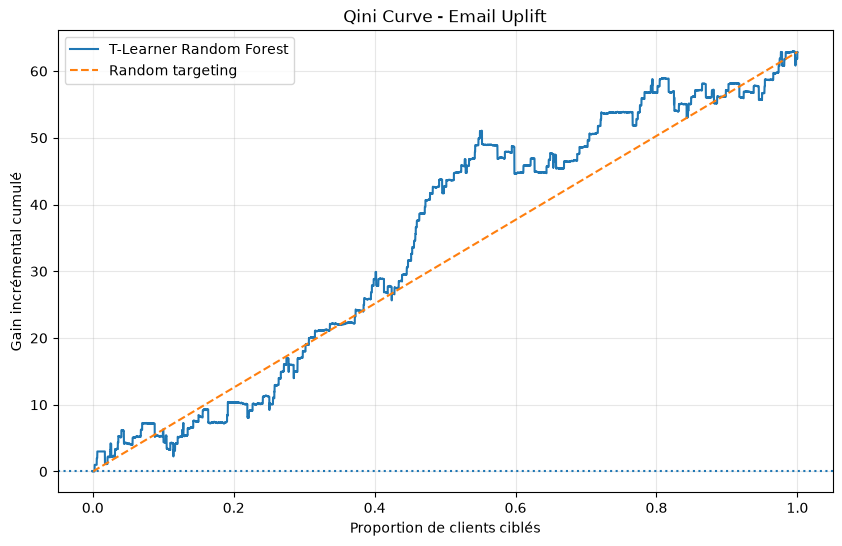

In [25]:
plt.figure(figsize=(10, 6))

plt.plot(
    results_sorted['population_fraction'],
    results_sorted['qini'].fillna(0),
    label='T-Learner Random Forest'
)

plt.plot(
    results_sorted['population_fraction'],
    results_sorted['random_baseline'],
    linestyle='--',
    label='Random targeting'
)

plt.axhline(
    0,
    linestyle=':'
)

plt.xlabel(
    'Proportion de clients ciblés'
)

plt.ylabel(
    'Gain incrémental cumulé'
)

plt.title(
    'Qini Curve - Email Uplift'
)

plt.legend()

plt.grid(alpha=0.3)

plt.show()

### Qini AUC

In [26]:
valid = (
    results_sorted['cum_control'] > 0
)

x = (
    results_sorted.loc[
        valid,
        'population_fraction'
    ]
)

qini_y = (
    results_sorted.loc[
        valid,
        'qini'
    ]
)

random_y = (
    results_sorted.loc[
        valid,
        'random_baseline'
    ]
)


model_auc = np.trapezoid(
    qini_y,
    x
)

random_auc = np.trapezoid(
    random_y,
    x
)

qini_coefficient = (
    model_auc - random_auc
)


print("====================================")
print("EVALUATION UPLIFT")
print("====================================")

print(
    f"Model Qini AUC : {model_auc:.4f}"
)

print(
    f"Random AUC     : {random_auc:.4f}"
)

print(
    f"Qini coefficient : {qini_coefficient:.4f}"
)

EVALUATION UPLIFT
Model Qini AUC : 34.2189
Random AUC     : 31.4305
Qini coefficient : 2.7883


Le T-learner superieur a modele au ciblage aleatoire,apporte une capacité de ciblage supérieure au ciblage aléatoire. 
Le coefficint de Qini est positif, ce qui indique que le modèle cible mieux les clients que le hasard.

In [27]:
results_sorted['decile'] = pd.qcut(
    results_sorted['uplift'],
    10,
    labels=False,
    duplicates='drop'
)


decile_analysis = (
    results_sorted
    .groupby('decile')
    .agg(
        clients=('conversion', 'size'),
        uplift_moyen=('uplift', 'mean'),
        taux_conversion=('conversion', 'mean'),
        taux_traitement=('treatment', 'mean')
    )
    .sort_index(ascending=False)
)


print("\n====================================")
print("ANALYSE PAR DECILE")
print("====================================")

print(decile_analysis)


ANALYSE PAR DECILE
        clients  uplift_moyen  taux_conversion  taux_traitement
decile                                                         
9          1920      0.019060         0.009375         0.657813
8          1920      0.011519         0.009896         0.668750
7          1920      0.008355         0.010417         0.672917
6          1920      0.006242         0.005729         0.672917
5          1920      0.004608         0.013542         0.671354
4          1920      0.003257         0.008854         0.667708
3          1920      0.002015         0.006771         0.665104
2          1920      0.000756         0.007292         0.664583
1          1920     -0.000955         0.009375         0.656250
0          1920     -0.005951         0.009375         0.673438


L'uplift moyen prédit diminue progressivement decile 9 à decile 0. Cela montre que le modèle distingue les clients selon leur bénéfice potentiel de la campagne. Les premiers déciles semblent donc plus intéressants à cibler. Cependant, les taux de conversion réellement observés varient d'un décile à l'autre et ne suivent pas exactement la même tendance, ce qui peut s'expliquer par le faible nombre de conversions.

In [28]:
print("\n====================================")
print("ANALYSE PAR POPULATION CIBLEE")
print("====================================")

for percentage in [0.10, 0.20, 0.30, 0.40, 0.50, 1.00]:

    n = int(
        len(results_sorted)
        * percentage
    )

    subset = results_sorted.iloc[:n]

    treated = subset[
        subset['treatment'] == 1
    ]

    control = subset[
        subset['treatment'] == 0
    ]

    if len(treated) > 0 and len(control) > 0:

        conversion_treated = (
            treated['conversion'].mean()
        )

        conversion_control = (
            control['conversion'].mean()
        )

        uplift_observe = (
            conversion_treated
            - conversion_control
        )

        print(
            f"Top {int(percentage*100):>3}% | "
            f"Traités = {len(treated):>4} | "
            f"Contrôles = {len(control):>4} | "
            f"Conv. traité = {conversion_treated:.4f} | "
            f"Conv. contrôle = {conversion_control:.4f} | "
            f"Différence = {uplift_observe:.4f}"
        )


ANALYSE PAR POPULATION CIBLEE
Top  10% | Traités = 1263 | Contrôles =  657 | Conv. traité = 0.0111 | Conv. contrôle = 0.0061 | Différence = 0.0050
Top  20% | Traités = 2547 | Contrôles = 1293 | Conv. traité = 0.0110 | Conv. contrôle = 0.0070 | Différence = 0.0040
Top  30% | Traités = 3839 | Contrôles = 1921 | Conv. traité = 0.0115 | Conv. contrôle = 0.0068 | Différence = 0.0047
Top  40% | Traités = 5131 | Contrôles = 2549 | Conv. traité = 0.0107 | Conv. contrôle = 0.0051 | Différence = 0.0056
Top  50% | Traités = 6420 | Contrôles = 3180 | Conv. traité = 0.0120 | Conv. contrôle = 0.0053 | Différence = 0.0066
Top 100% | Traités = 12808 | Contrôles = 6392 | Conv. traité = 0.0107 | Conv. contrôle = 0.0058 | Différence = 0.0049


En ciblant différentes proportions de clients selon leur uplift, la différence de conversion reste positive. Elle est de +0,66 point de pourcentage pour le Top 50 %, contre +0,49 point pour l'ensemble des clients. Le Top 50 % donne le meilleur résultat parmi les seuils testés, mais cela ne signifie pas forcément que c'est le seuil optimal. Le choix du seuil dépend aussi des objectifs de la campagne.

### Exemple operationnel

In [29]:
top30 = results_sorted.head(
    int(len(results_sorted) * 0.30)
)

print("Top 30 % :", len(top30))

Top 30 % : 5760


J'ai sélectionné 5 760 clients, soit les 30 % ayant les scores d'uplift les plus élevés.


In [30]:
#pour le variables numeriques 
profil = pd.DataFrame({
    'Top 30 %': top30[['recency', 'history', 'newbie']].mean(),
    'Reste': results_sorted[
        ~results_sorted.index.isin(top30.index)
    ][['recency', 'history', 'newbie']].mean()
})

print(profil)

           Top 30 %       Reste
recency    5.181597    6.039211
history  376.990099  186.011761
newbie     0.659201    0.440848


Par rapport au reste des clients, cette population a en moyenne un historique d'achat plus élevé (377$ contre 186 $), une récence plus faible (5,18 contre 6,04) et une proportion plus importante de nouveaux clients (66 % contre 44 %).
Ces caractéristiques décrivent les clients que le modèle considère comme les plus susceptibles de bénéficier de la campagne email.

In [31]:
print(
    pd.crosstab(
        top30['history_segment'],
        columns='proportion',
        normalize=True
    )
)

print(
    pd.crosstab(
        top30['channel'],
        columns='proportion',
        normalize=True
    )
)

print(
    pd.crosstab(
        top30['zip_code'],
        columns='proportion',
        normalize=True
    )
)

col_0             proportion
history_segment             
1) $0 - $100        0.315451
2) $100 - $200      0.145139
3) $200 - $350      0.140278
4) $350 - $500      0.053819
5) $500 - $750      0.192188
6) $750 - $1,000    0.092014
7) $1,000 +         0.061111
col_0         proportion
channel                 
Multichannel    0.184549
Phone           0.343750
Web             0.471701
col_0      proportion
zip_code             
Rural        0.180035
Surburban    0.460417
Urban        0.359549


Le canal Web est le plus représenté (47,2 %) et la zone Suburban est majoritaire (46,0 %).

In [32]:
print(top30[['mens', 'womens']].mean())

mens      0.521354
womens    0.679688
dtype: float64


l'indicateur womens est présent chez 68,0 % de cette population, contre 52,1 % pour l'indicateur mens. Cela décrit simplement la composition de la population ayant les scores d'uplift les plus élevés.

### Conclusion

L'analyse permet d'estimer l'effet potentiel de l'email pour chaque client grâce au score d'uplift. Les clients sont ensuite classés selon cet effet estimé. Les premiers déciles présentent les scores d'uplift les plus élevés, ce qui permet d'identifier les clients pour lesquels la campagne semble avoir le plus d'effet.
Ainsi, le modèle répond à l'objectif initial : identifier les clients les plus susceptibles de bénéficier de la campagne email, plutôt que de cibler tous les clients de la même manière.